# EDA: Titanic, quem sobreviveu e por quê?

**Problema de negócio:** entender quais características dos passageiros estão associadas à sobrevivência, para guiar a criação do modelo de classificação (`03_modelos`).

**Target:** `Survived` (1 = sobreviveu, 0 = não sobreviveu).

### Como usar este notebook
- Rode célula por célula (**Shift + Enter**) e **leia a saída antes de seguir**. EDA é conversa com o dado, não script.
- Cada seção tem: o que fazer, por que fazer, o código e um bloco **💡 Dica** ou **🧠 Hipótese**.
- Onde houver **✍️ Sua vez**, escreva com suas palavras o que você observou. Esse texto é o que o recrutador vai ler.

### Índice
1. Setup
2. Carregar e separar treino/teste
3. Visão geral dos dados
4. Qualidade dos dados (nulos, duplicatas, valores absurdos)
5. 🧭 Guia: qual gráfico usar e quando
6. O target
7. Variáveis numéricas (uma por vez) e outliers
8. Variáveis categóricas (uma por vez)
9. Cada variável vs o target
10. Relações entre várias variáveis
11. Ideias de novas features
12. Testes de hipótese
13. Conclusões e próximos passos

## 1. Setup

Importamos as bibliotecas e fixamos a semente (`SEED`) para o resultado ser **reprodutível**: qualquer pessoa que rodar chega nos mesmos números.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, mannwhitneyu
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")      # deixa a saída limpa (não use isso para esconder erros reais!)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)

SEED = 42
COR_MORREU = "#c0392b"   # vermelho
COR_VIVEU = "#2980b9"    # azul
PALETA_SURV = {"Morreu": COR_MORREU, "Sobreviveu": COR_VIVEU}   # mesma cor para o mesmo significado em TODOS os gráficos

> 💡 **Dica (cores com significado):** use sempre a mesma cor para a mesma coisa (aqui: vermelho = morreu, azul = sobreviveu). Quem olha o 5º gráfico não precisa reler a legenda.

## 2. Carregar e separar treino/teste

**Antes de explorar, separe o teste.** A partir daqui, toda análise usa só o `train`. O `test` fica guardado até a avaliação final.

**Por quê?** Se você olhar o teste para decidir como tratar variáveis, a informação dele "vaza" para o modelo (*data leakage*) e a nota final fica otimista demais.

> Baixe o `train.csv` do Titanic no Kaggle e salve em `data/train.csv` (na raiz do repositório). Não suba o arquivo para o Git: adicione `data/` ao `.gitignore` e explique no README como baixar.

In [2]:
df = pd.read_csv("../data/train.csv")

# stratify=df["Survived"] mantém a mesma proporção de sobreviventes nos dois grupos
train, test = train_test_split(
    df, test_size=0.2, stratify=df["Survived"], random_state=SEED
)
train = train.copy()

# coluna de texto só para os gráficos (rótulos e cores legíveis)
train["Desfecho"] = train["Survived"].map({0: "Morreu", 1: "Sobreviveu"})

print("Dados completos:", df.shape)
print("Treino (vamos explorar):", train.shape)
print("Teste (NÃO mexer):", test.shape)

Dados completos: (891, 12)
Treino (vamos explorar): (712, 13)
Teste (NÃO mexer): (179, 12)


## 3. Visão geral dos dados

Primeiro contato: quantas linhas e colunas, que tipos, e como os dados se parecem.

### Dicionário de dados (sempre escreva um!)
| Coluna | Significado | Tipo |
|---|---|---|
| `PassengerId` | identificador | número (não é feature) |
| `Survived` | **target** (0/1) | categórica binária |
| `Pclass` | classe da passagem (1ª, 2ª, 3ª) | categórica **ordinal** |
| `Name` | nome (contém o título: Mr, Mrs...) | texto |
| `Sex` | sexo | categórica |
| `Age` | idade em anos | numérica contínua |
| `SibSp` | irmãos + cônjuge a bordo | numérica discreta |
| `Parch` | pais + filhos a bordo | numérica discreta |
| `Ticket` | número do bilhete | texto |
| `Fare` | tarifa paga | numérica contínua |
| `Cabin` | cabine | texto |
| `Embarked` | porto de embarque (C, Q, S) | categórica |

> 💡 **Dica:** saber o **tipo** de cada variável (numérica contínua, discreta, categórica nominal, ordinal) decide qual gráfico e qual teste usar. Veja a seção 5.

* Variável discreta -> obtida por contagem, geralmente expressos em números inteiros
* Variável contínua -> valores obtidos por mediação, podendo assumir infinitos valores dentro de um intervalo real. ex: massa corporal, altura etc.

In [3]:
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Desfecho
692,693,1,3,"Lam, Mr. Ali",male,NaN,0,0,1601,56.4958,NaN,S,Sobreviveu
481,482,0,2,"Frost, Mr. Anthony Wood ""Archie""",male,NaN,0,0,239854,0.0000,NaN,S,Morreu
527,528,0,1,"Farthing, Mr. John",male,NaN,0,0,PC 17483,221.7792,C95,S,Morreu
855,856,1,3,"Aks, Mrs. Sam (Leah Rosen)",female,18.0,0,1,392091,9.3500,NaN,S,Sobreviveu
801,802,1,2,"Collyer, Mrs. Harvey (Charlotte Annie Tate)",female,31.0,1,1,C.A. 31921,26.2500,NaN,S,Sobreviveu


In [4]:
train.info()

<class 'pandas.DataFrame'>
Index: 712 entries, 692 to 507
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  712 non-null    int64  
 1   Survived     712 non-null    int64  
 2   Pclass       712 non-null    int64  
 3   Name         712 non-null    str    
 4   Sex          712 non-null    str    
 5   Age          575 non-null    float64
 6   SibSp        712 non-null    int64  
 7   Parch        712 non-null    int64  
 8   Ticket       712 non-null    str    
 9   Fare         712 non-null    float64
 10  Cabin        160 non-null    str    
 11  Embarked     710 non-null    str    
 12  Desfecho     712 non-null    str    
dtypes: float64(2), int64(5), str(6)
memory usage: 77.9 KB


In [5]:
# Resumo estatístico das numéricas: olhe média vs mediana (50%) e o mínimo/máximo
train.describe().T

,count,mean,std,min,25%,50%,75%,max
PassengerId,712.0,444.405899,257.465527,1.00,222.7500,439.5000,667.25,891.0000
Survived,712.0,0.383427,0.486563,0.00,0.0000,0.0000,1.00,1.0000
Pclass,712.0,2.308989,0.833563,1.00,2.0000,3.0000,3.00,3.0000
Age,575.0,29.807687,14.485211,0.42,21.0000,28.5000,39.00,80.0000
SibSp,712.0,0.492978,1.060720,0.00,0.0000,0.0000,1.00,8.0000
Parch,712.0,0.390449,0.838134,0.00,0.0000,0.0000,0.00,6.0000
Fare,712.0,31.819826,48.059104,0.00,7.8958,14.4542,31.00,512.3292


In [6]:
# Resumo das categóricas
train.describe(include=["object", "string"]).T

,count,unique,top,freq
Name,712,712,"Lam, Mr. Ali",1
Sex,712,2,male,459
Ticket,712,571,1601,6
Cabin,160,127,G6,4
Embarked,710,3,S,516
Desfecho,712,2,Morreu,439


✍️ **Sua vez:** escreva 2 a 3 observações. Exemplo de perguntas: *Há colunas com muitos nulos? A média de `Fare` é bem maior que a mediana? Alguma coluna parece não servir para o modelo?*

## 4. Qualidade dos dados

Antes de tirar conclusões, confirme que o dado é confiável: **nulos, duplicatas e valores impossíveis**.

### 4.1 Valores nulos

% de nulos por coluna:
Cabin       77.5
Age         19.2
Embarked     0.3
dtype: float64


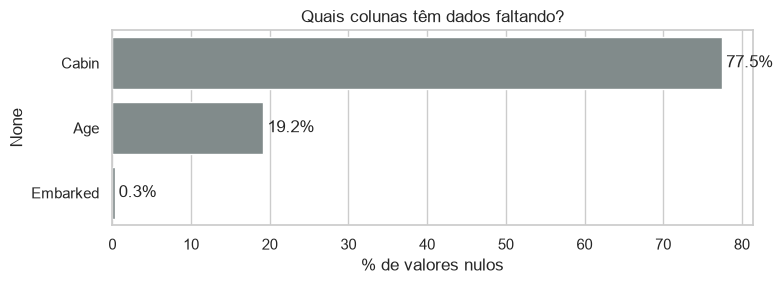

In [7]:
nulos = (train.isna().mean() * 100).round(1).sort_values(ascending=False)
nulos = nulos[nulos > 0]
print("% de nulos por coluna:")
print(nulos)

fig, ax = plt.subplots(figsize=(8, 3))
sns.barplot(x=nulos.values, y=nulos.index, color="#7f8c8d", ax=ax)
ax.set_xlabel("% de valores nulos")
ax.set_title("Quais colunas têm dados faltando?")
for i, v in enumerate(nulos.values):
    ax.text(v + 0.5, i, f"{v}%", va="center")
plt.tight_layout()
plt.show()

**Como decidir o que fazer com nulos** (a decisão depende de *quanto* falta e *por quê*):

| Situação | Opção comum |
|---|---|
| Quase tudo vazio (>70%), como `Cabin` | Descartar a coluna **ou** criar um indicador "tem / não tem" |
| Numérica com poucos nulos, como `Age` | Preencher com a **mediana** (robusta a outliers) |
| Categórica com poucos nulos, como `Embarked` | Preencher com a **moda** (valor mais comum) |

> 🧠 **Hipótese sobre nulos:** o dado pode estar faltando **por um motivo**. Quem não tem cabine registrada pode ser de classe mais baixa. Se for isso, o fato de ser nulo *é informação*. Teste na seção 11.

> ⚠️ **Regra de ouro:** a mediana/moda usada para preencher é calculada **só no treino** e aplicada no treino e no teste. Faremos isso no notebook de modelagem.

In [8]:
# Os nulos de Age têm relação com a sobrevivência? (se tiver, "ser nulo" é informação)
train.groupby(train["Age"].isna())["Survived"].agg(["mean", "count"]).rename(
    index={False: "Idade informada", True: "Idade NULA"}
)

,mean,count
Age,,
Idade informada,0.405217,575
Idade NULA,0.291971,137


### 4.2 Duplicatas e valores impossíveis

In [9]:
print("Linhas duplicadas:", train.duplicated().sum())
print("PassengerId duplicado:", train["PassengerId"].duplicated().sum())
print("Idades <= 0 ou > 100:", ((train["Age"] <= 0) | (train["Age"] > 100)).sum())
print("Tarifas = 0:", (train["Fare"] == 0).sum())
print("Tarifas negativas:", (train["Fare"] < 0).sum())

Linhas duplicadas: 0
PassengerId duplicado: 0
Idades <= 0 ou > 100: 0
Tarifas = 0: 14
Tarifas negativas: 0


> 💡 **Dica (checklist de qualidade):** sempre pergunte (1) tem nulo? (2) tem duplicata? (3) tem valor impossível (idade negativa, data no futuro)? (4) os tipos estão certos (número guardado como texto)? (5) categorias iguais escritas de formas diferentes ("SP", "sp", "São Paulo")?

Tarifas iguais a 0 podem ser tripulação ou erro de registro. **Anote a dúvida** e decida depois (o `Fare = 0` é raro; aqui deixaremos como está).

## 5. 🧭 Guia: qual gráfico usar e quando

Antes de plotar, faça **duas perguntas**:
1. **Qual é o tipo de cada variável?** (numérica ou categórica)
2. **O que eu quero ver?** (distribuição, comparação, relação ou composição)

| O que eu quero ver | Variáveis | Gráfico | Quando usar |
|---|---|---|---|
| **Distribuição** de 1 numérica | 1 numérica | **Histograma** (+ curva KDE) | Ver formato, assimetria, picos |
| Distribuição + outliers | 1 numérica | **Boxplot** | Ver mediana, quartis e outliers rapidamente |
| Distribuição comparada entre grupos | 1 numérica + 1 categórica | **Violin** ou **boxplot por grupo** | Comparar formato entre grupos (violin mostra a forma toda) |
| **Contagem** de categorias | 1 categórica | **Barras (countplot)** | Quantos de cada categoria |
| **Taxa/média** por categoria | 1 categórica + target | **Barras com taxa (barplot)** | Ex.: % de sobreviventes por classe (as barras de erro mostram a incerteza) |
| **Composição** (proporção dentro do grupo) | 2 categóricas | **Barras empilhadas 100%** ou **heatmap de taxas** | Comparar proporções entre grupos |
| **Relação** entre 2 numéricas | 2 numéricas | **Dispersão (scatter)** | Ver tendência, grupos, outliers |
| Relação entre **muitas** numéricas | várias numéricas | **Heatmap de correlação** | Visão geral de quem se relaciona com quem |
| 3 ou mais variáveis | misto | **Facetas** (`catplot`, `FacetGrid`) ou **cor/tamanho** no scatter | Comparar um padrão entre subgrupos |

**Regras que evitam gráficos ruins:**
- **Pizza:** evite. Barras são mais fáceis de comparar.
- **Eixo Y de barras começa no zero.** Cortar o eixo exagera diferenças.
- **Muita sobreposição de pontos?** Use transparência (`alpha`) ou prefira histograma/violin.
- **Título que diga a conclusão** ("Mulheres sobreviveram 4x mais que homens") é melhor que título genérico ("Sobrevivência por sexo").
- **Se o gráfico precisa de explicação longa, ele está errado.** Simplifique.

> 💡 **Teste mental:** *"se eu mostrar este gráfico para alguém sem contexto, em 5 segundos ela entende a mensagem?"*

## 6. O target (`Survived`)

Sempre comece pelo que você quer prever: **está balanceado?** Isso define quais métricas usar depois (lembra da pegadinha da acurácia?).

          qtd     %
Survived           
0         439  61.7
1         273  38.3


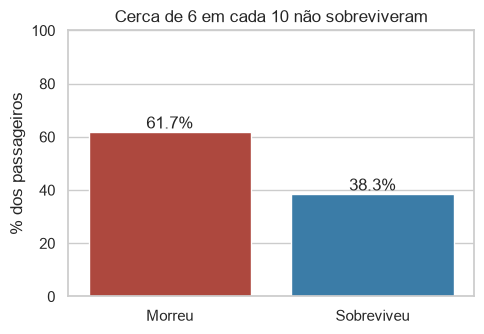


Baseline 'burro' (sempre prever a classe majoritária): 61.7% de acurácia


In [10]:
contagem = train["Survived"].value_counts().sort_index()
pct = train["Survived"].value_counts(normalize=True).sort_index() * 100
print(pd.DataFrame({"qtd": contagem, "%": pct.round(1)}))

fig, ax = plt.subplots(figsize=(5, 3.5))
sns.barplot(x=["Morreu", "Sobreviveu"], y=pct.values, hue=["Morreu", "Sobreviveu"],
            palette=PALETA_SURV, legend=False, ax=ax)
ax.set_ylabel("% dos passageiros")
ax.set_ylim(0, 100)
ax.set_title("Cerca de 6 em cada 10 não sobreviveram")
for i, v in enumerate(pct.values):
    ax.text(i, v + 1.5, f"{v:.1f}%", ha="center")
plt.tight_layout()
plt.show()

print(f"\nBaseline 'burro' (sempre prever a classe majoritária): {pct.max():.1f}% de acurácia")

> 💡 **Dica:** esse "baseline burro" é a régua mínima. Um modelo com 70% de acurácia parece bom, mas só ganha ~8 pontos de quem chuta sempre "morreu".

## 7. Variáveis numéricas (uma por vez)

**Objetivo:** entender o formato da distribuição de `Age` e `Fare`: simétrica? assimétrica? tem outliers?

**Histograma + KDE + boxplot juntos** mostram o formato (histograma) e os extremos (boxplot).

In [11]:
def resumo_numerica(serie):
    # Resumo com média, mediana, desvio e assimetria (skew).
    return pd.Series({
        "média": serie.mean(),
        "mediana": serie.median(),
        "desvio padrão": serie.std(),
        "assimetria (skew)": serie.skew(),
        "mín": serie.min(),
        "máx": serie.max(),
    }).round(2)

pd.DataFrame({"Age": resumo_numerica(train["Age"]),
              "Fare": resumo_numerica(train["Fare"])})

,Age,Fare
média,29.81,31.82
mediana,28.50,14.45
desvio padrão,14.49,48.06
assimetria (skew),0.35,4.65
mín,0.42,0.00
máx,80.00,512.33


> 💡 **Como ler o `skew` (assimetria):** perto de 0 = simétrica. **Positivo e alto** (> 1) = cauda longa à direita (poucos valores muito altos puxando a média). Se **média > mediana** em muito, é o mesmo sinal.

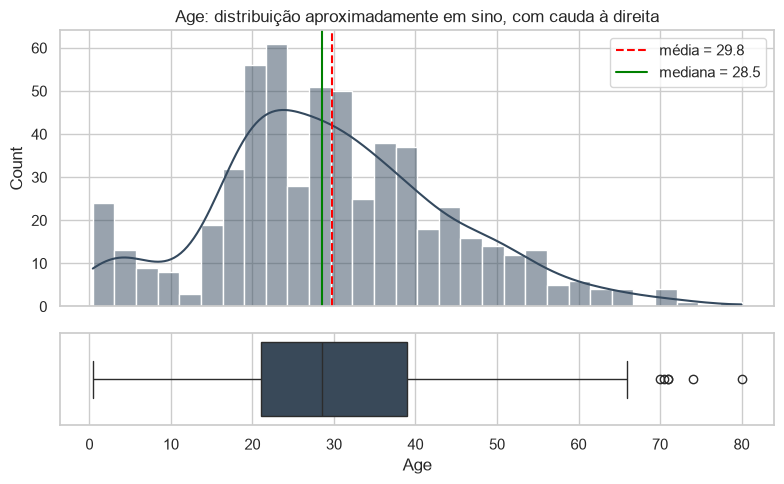

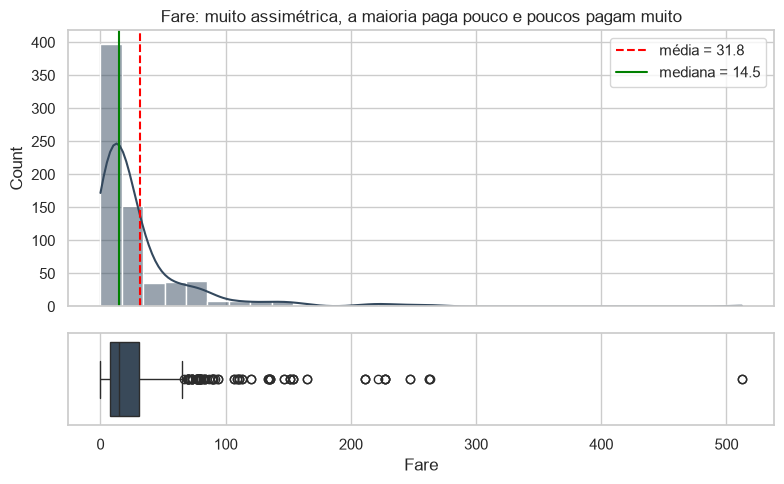

In [12]:
def plot_numerica(coluna, titulo, cor="#34495e"):
    # Histograma com KDE (em cima) e boxplot (embaixo) da mesma variável.
    fig, (ax1, ax2) = plt.subplots(
        2, 1, figsize=(8, 5), sharex=True,
        gridspec_kw={"height_ratios": [3, 1]}
    )
    dados = train[coluna].dropna()
    sns.histplot(dados, bins=30, kde=True, color=cor, ax=ax1)
    ax1.axvline(dados.mean(), color="red", ls="--", label=f"média = {dados.mean():.1f}")
    ax1.axvline(dados.median(), color="green", ls="-", label=f"mediana = {dados.median():.1f}")
    ax1.legend()
    ax1.set_title(titulo)
    sns.boxplot(x=dados, color=cor, ax=ax2)
    ax2.set_xlabel(coluna)
    plt.tight_layout()
    plt.show()

plot_numerica("Age", "Age: distribuição aproximadamente em sino, com cauda à direita")
plot_numerica("Fare", "Fare: muito assimétrica, a maioria paga pouco e poucos pagam muito")

✍️ **Sua vez:** compare as linhas de média e mediana em `Fare`. O que a distância entre elas diz? (Dica: assimetria à direita.)

### 7.1 Outliers em `Fare`

**Regra do IQR:** é outlier o que fica fora de `[Q1 − 1,5·IQR, Q3 + 1,5·IQR]`, em que IQR = Q3 − Q1.

In [13]:
def outliers_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    inf, sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (serie < inf) | (serie > sup)
    return inf, sup, mask

inf, sup, mask = outliers_iqr(train["Fare"])
print(f"Limites: [{inf:.1f}, {sup:.1f}] | outliers em Fare: {mask.sum()} ({mask.mean()*100:.1f}%)")

# Quem são os "outliers"? Erros de digitação ou passageiros de luxo?
print("\nClasse dos outliers de Fare:")
print(train.loc[mask, "Pclass"].value_counts(normalize=True).round(2))

print("\nTarifa máxima:")
train.loc[train["Fare"].nlargest(3).index, ["Name", "Pclass", "Fare", "Survived"]]

Limites: [-26.8, 65.7] | outliers em Fare: 91 (12.8%)

Classe dos outliers de Fare:
Pclass
1    0.89
3    0.05
2    0.05
Name: proportion, dtype: float64

Tarifa máxima:


,Name,Pclass,Fare,Survived
737,"Lesurer, Mr. Gustave J",1,512.3292,1
258,"Ward, Miss. Anna",1,512.3292,1
438,"Fortune, Mr. Mark",1,263.0000,0


**Decisão (exemplo de como registrar):** *"Os outliers de `Fare` são majoritariamente de 1ª classe; são valores reais, não erros. Vou **manter** e aplicar `log1p` para reduzir a assimetria."*

> 💡 **Dica (o que fazer com outliers):** (1) **Investigue primeiro**, nunca apague no automático. (2) Se for erro, corrija ou remova. (3) Se for real e raro, **mantenha** e, se distorcer, use transformação (`log`) ou um modelo robusto (árvores). (4) **Sempre registre a decisão** no notebook.

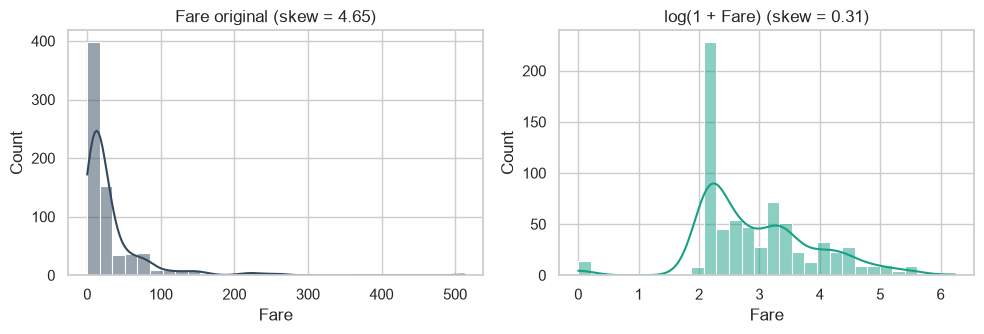

In [14]:
# Efeito do log: reduz a assimetria
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
sns.histplot(train["Fare"], bins=30, kde=True, ax=axes[0], color="#34495e")
axes[0].set_title(f"Fare original (skew = {train['Fare'].skew():.2f})")
sns.histplot(np.log1p(train["Fare"]), bins=30, kde=True, ax=axes[1], color="#16a085")
axes[1].set_title(f"log(1 + Fare) (skew = {np.log1p(train['Fare']).skew():.2f})")
plt.tight_layout()
plt.show()

> 💡 **Por que `log1p` e não `log`?** `log(0)` não existe, e há tarifas iguais a 0. `log1p(x) = log(1 + x)` funciona com zero.

## 8. Variáveis categóricas (uma por vez)

Para categorias, o gráfico certo é **barras de contagem**. Olhe se alguma categoria é **muito rara** (pode virar ruído ou precisar ser agrupada).

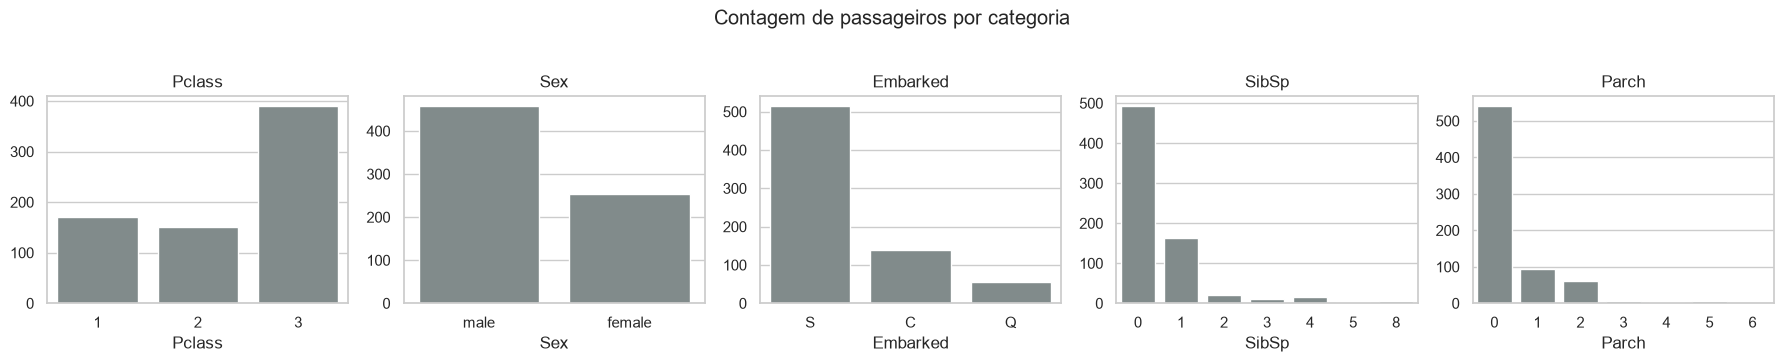

In [15]:
colunas_cat = ["Pclass", "Sex", "Embarked", "SibSp", "Parch"]

fig, axes = plt.subplots(1, 5, figsize=(18, 3.5))
for ax, col in zip(axes, colunas_cat):
    sns.countplot(data=train, x=col, color="#7f8c8d", ax=ax)
    ax.set_title(col)
    ax.set_ylabel("")
plt.suptitle("Contagem de passageiros por categoria", y=1.03)
plt.tight_layout()
plt.show()

✍️ **Sua vez:** qual classe (`Pclass`) tem mais passageiros? A maioria viaja sozinha (`SibSp` e `Parch` = 0)? Alguma categoria é muito rara?

> 💡 **Dica:** `Pclass` é um número (1, 2, 3), mas é **categoria ordinal**: não faz sentido "média de classe". Trate como categoria nos gráficos.

## 9. Cada variável vs o target

Aqui nascem os **insights**. A pergunta é: *"essa variável ajuda a separar quem sobreviveu de quem não sobreviveu?"*

### 9.1 Categóricas vs target → **taxa de sobrevivência por grupo**

Para variável categórica contra um target 0/1, o gráfico ideal é **barras com a taxa (média do target)**. As linhas pretas nas barras são o intervalo de confiança: **se os intervalos de duas barras não se sobrepõem, a diferença provavelmente é real.**

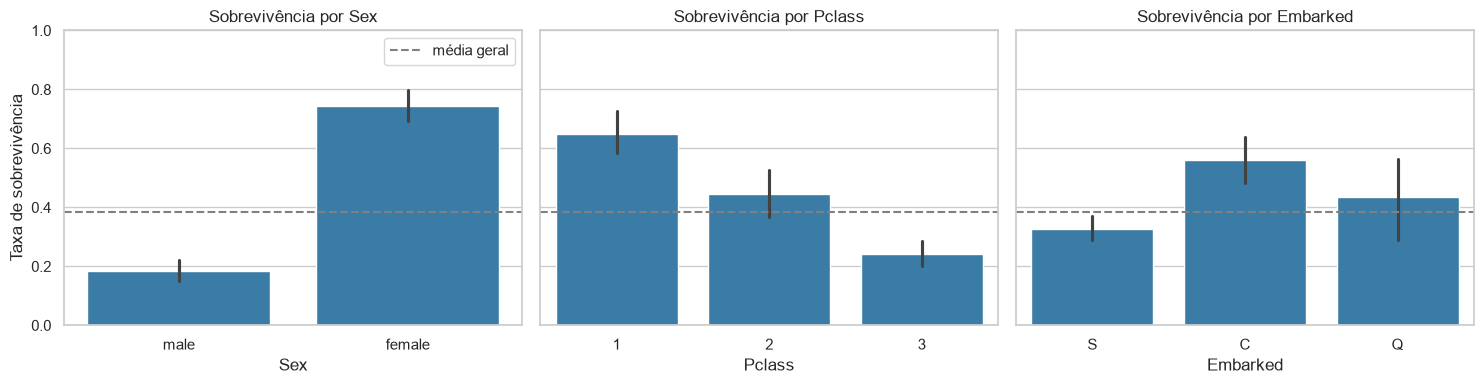

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, col in zip(axes, ["Sex", "Pclass", "Embarked"]):
    sns.barplot(data=train, x=col, y="Survived", color="#2980b9", ax=ax)
    ax.axhline(train["Survived"].mean(), color="gray", ls="--", label="média geral")
    ax.set_title(f"Sobrevivência por {col}")
    ax.set_ylabel("Taxa de sobrevivência")
    ax.set_ylim(0, 1)
axes[0].legend()
plt.tight_layout()
plt.show()

In [17]:
# Mesmos números em tabela (gráfico mostra, tabela confirma)
for col in ["Sex", "Pclass", "Embarked"]:
    t = train.groupby(col)["Survived"].agg(taxa="mean", n="count").round(3)
    print(f"--- {col} ---")
    print(t, "\n")

--- Sex ---
         taxa    n
Sex               
female  0.743  253
male    0.185  459 

--- Pclass ---
         taxa    n
Pclass            
1       0.649  171
2       0.447  150
3       0.243  391 

--- Embarked ---
           taxa    n
Embarked            
C         0.561  139
Q         0.436   55
S         0.328  516 



> 🧠 **Hipótese 1: "mulheres sobreviveram mais que homens".**
> *Por quê?* Protocolo de evacuação ("mulheres e crianças primeiro"). *Como testar:* taxa por sexo (acima) + teste qui-quadrado (seção 12).
>
> 🧠 **Hipótese 2: "quanto melhor a classe, maior a sobrevivência".**
> *Por quê?* Cabines da 1ª classe ficavam mais perto dos botes. *Como testar:* taxa por `Pclass` + qui-quadrado.
>
> 🧠 **Hipótese 3: "o porto de embarque influencia".** Provavelmente é **efeito indireto** (cada porto tem mistura diferente de classes). Veja a seção 10 para checar.

> 💡 **Dica (como elaborar hipóteses você mesma):** use o formato **"Se [variável], então [efeito no target], porque [motivo plausível]"**. O *"porque"* é o mais importante: se você não consegue explicar o motivo, pode ser coincidência. Depois pergunte: *"qual gráfico ou teste confirmaria ou derrubaria isso?"*

### 9.2 Numéricas vs target → **comparar distribuições entre os grupos**

Para numérica contra target 0/1, compare **a distribuição de cada grupo**. O violin mostra a forma completa; o boxplot mostra mediana e quartis.

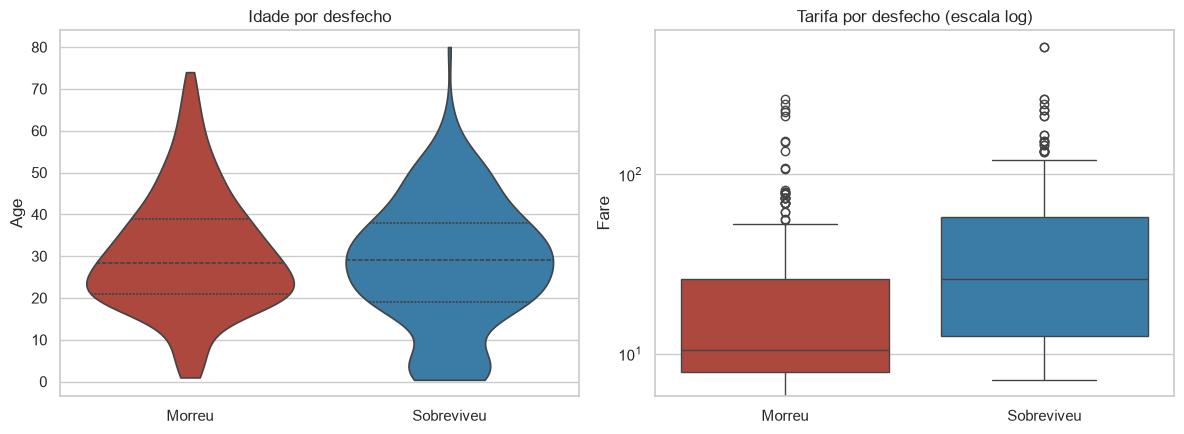

             Age  Fare
Survived              
Morreu      28.2  10.5
Sobreviveu  29.0  26.0


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.violinplot(data=train, x="Desfecho", y="Age", hue="Desfecho", palette=PALETA_SURV,
               order=["Morreu", "Sobreviveu"], hue_order=["Morreu", "Sobreviveu"],
               inner="quartile", cut=0, legend=False, ax=axes[0])
axes[0].set_xlabel("")
axes[0].set_title("Idade por desfecho")

sns.boxplot(data=train, x="Desfecho", y="Fare", hue="Desfecho", palette=PALETA_SURV,
            order=["Morreu", "Sobreviveu"], hue_order=["Morreu", "Sobreviveu"],
            legend=False, ax=axes[1])
axes[1].set_yscale("log")            # escala log por causa da assimetria
axes[1].set_xlabel("")
axes[1].set_title("Tarifa por desfecho (escala log)")
plt.tight_layout()
plt.show()

print(train.groupby("Survived")[["Age", "Fare"]].median().round(1).rename(index={0: "Morreu", 1: "Sobreviveu"}))

> 💡 **Dica (violin):** `cut=0` impede que a curva "suavizada" passe do mínimo e do máximo reais (sem ele, o violin poderia mostrar idades negativas). **Boxplot em escala log:** tarifas iguais a 0 não aparecem, porque `log(0)` não existe (são só 14 passageiros).

> 💡 **Dica (escala log):** quando a variável é muito assimétrica, a escala log no eixo deixa os grupos comparáveis (sem ela, quase tudo fica "esmagado" embaixo). Avise sempre que usar: *"escala log"* no título.

> 🧠 **Hipótese 4: "crianças sobreviveram mais".** O violin de idade é parecido para os dois grupos, mas **a média esconde o efeito nas crianças**. Quando o efeito está em uma faixa específica (e não na variável inteira), transforme em **faixas** e compare taxas:

                       taxa    n
FaixaIdade                      
Criança (0-12)        0.600   55
Adolescente (13-18)   0.415   53
Adulto jovem (19-35)  0.377  284
Adulto (36-60)        0.407  167
Idoso (60+)           0.188   16


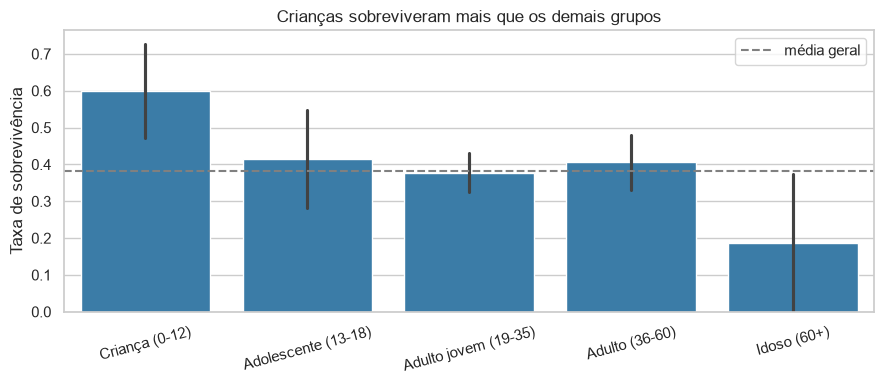

In [19]:
faixas = [0, 12, 18, 35, 60, 100]
rotulos = ["Criança (0-12)", "Adolescente (13-18)", "Adulto jovem (19-35)", "Adulto (36-60)", "Idoso (60+)"]
train["FaixaIdade"] = pd.cut(train["Age"], bins=faixas, labels=rotulos)

taxa_faixa = train.groupby("FaixaIdade", observed=True)["Survived"].agg(taxa="mean", n="count")
print(taxa_faixa.round(3))

fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=train, x="FaixaIdade", y="Survived", color="#2980b9", ax=ax)
ax.axhline(train["Survived"].mean(), color="gray", ls="--", label="média geral")
ax.set_title("Crianças sobreviveram mais que os demais grupos")
ax.set_ylabel("Taxa de sobrevivência")
ax.set_xlabel("")
ax.legend()
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

> 💡 **Dica:** quando uma numérica "não parece ter efeito" no geral, **teste faixas**. Efeitos concentrados em um subgrupo somem na média. Cuidado: faixas com poucos passageiros (olhe a coluna `n`) dão taxas instáveis.

✍️ **Sua vez:** escolha outros cortes de idade (ex.: 0-5, 6-12) e veja se o padrão se mantém. Se mudar muito com o corte, o resultado é frágil.

## 10. Relações entre várias variáveis

Um insight de uma variável isolada pode ser **enganoso**. Aqui cruzamos variáveis para separar efeitos.

### 10.1 Sexo × Classe → **heatmap de taxas**

Para duas categóricas e um target, o **heatmap de taxas** mostra de uma vez onde o efeito é mais forte.

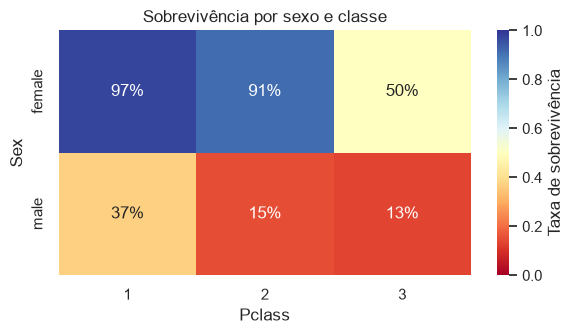

Passageiros em cada célula (n):
Pclass   1   2    3
Sex                
female  79  58  116
male    92  92  275


In [20]:
pivot = train.pivot_table(values="Survived", index="Sex", columns="Pclass", aggfunc="mean")
contagem = train.pivot_table(values="Survived", index="Sex", columns="Pclass", aggfunc="count")

fig, ax = plt.subplots(figsize=(6, 3.5))
sns.heatmap(pivot, annot=True, fmt=".0%", cmap="RdYlBu", vmin=0, vmax=1,
            cbar_kws={"label": "Taxa de sobrevivência"}, ax=ax)
ax.set_title("Sobrevivência por sexo e classe")
plt.tight_layout()
plt.show()

print("Passageiros em cada célula (n):")
print(contagem)

> 💡 **Dica:** sempre olhe o `n` (tamanho) de cada célula. Uma taxa de 100% com 3 pessoas não vale nada.

> 🧠 **Insight esperado:** o efeito do sexo é enorme **dentro de todas as classes**. Mulheres da 1ª e 2ª classe sobrevivem em ~90% ou mais, enquanto as da 3ª ficam em ~50%. Já entre os homens, a 1ª classe (~37%) sobrevive bem mais que a 2ª e a 3ª (~15%). Sexo e classe têm efeito **combinado** (interação): o peso da classe depende do sexo. É por isso que modelos de árvore costumam ir bem aqui.

### 10.2 Facetas: o mesmo gráfico para vários subgrupos

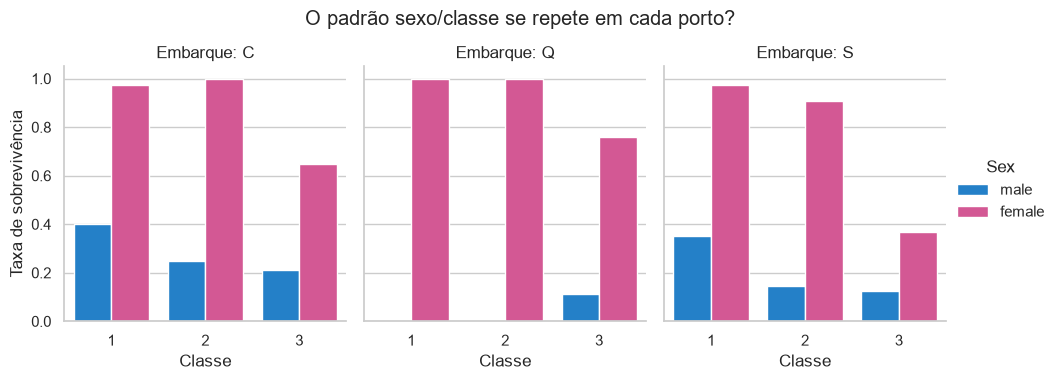

In [21]:
g = sns.catplot(
    data=train, x="Pclass", y="Survived", hue="Sex", col="Embarked",
    kind="bar", col_order=["C", "Q", "S"], height=3.6, aspect=0.9, errorbar=None,
    palette={"female": "#e84393", "male": "#0984e3"}
)
g.set_axis_labels("Classe", "Taxa de sobrevivência")
g.set_titles("Embarque: {col_name}")
g.figure.suptitle("O padrão sexo/classe se repete em cada porto?", y=1.05)
plt.show()

> 💡 **Quando usar facetas (`col=`/`row=`):** quando você quer saber se um padrão **se mantém em cada subgrupo**. Se o padrão aparece igual em todos, ele é robusto. Aqui, o padrão "mulheres > homens" e "1ª classe > 3ª" se repete nos três portos, e o efeito do embarque **diminui bastante** quando separamos por classe e sexo (em parte, `Embarked` é efeito **indireto**: cada porto tem uma mistura diferente de classes). Mas **não some por completo**: entre as mulheres da 3ª classe, as que embarcaram em Southampton (S) sobreviveram bem menos que as de C e Q. Guarde isso como **hipótese a investigar**.
>
> ⚠️ **Cuidado com o `n`:** o porto Q tem poucos passageiros em algumas classes (barras com 1 ou 2 pessoas, de 0% ou 100%). Confira os tamanhos antes de concluir qualquer coisa. (Em Q não há nenhum homem de 1ª classe, por isso essa barra nem aparece.)

### 10.3 Idade × Tarifa → **dispersão com cor**

Para duas numéricas, use dispersão. Adicione a **cor** do target para ver se os grupos se separam.

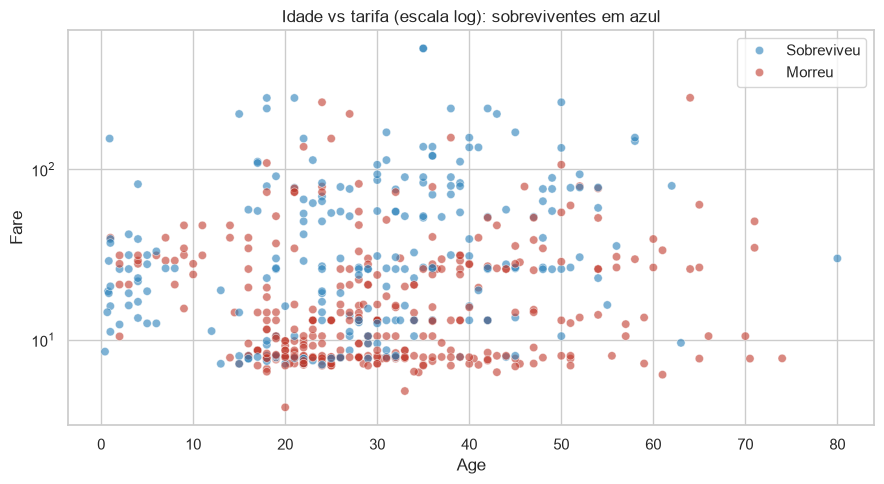

In [22]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(data=train, x="Age", y="Fare", hue="Desfecho",
                palette=PALETA_SURV, alpha=0.6, ax=ax)
ax.set_yscale("log")
ax.set_title("Idade vs tarifa (escala log): sobreviventes em azul")
ax.legend(title="")
plt.tight_layout()
plt.show()

> 💡 **Dica:** `alpha=0.6` deixa os pontos semi-transparentes: onde há sobreposição a cor fica mais forte, e você percebe a densidade. Se ainda assim ficar ilegível, use um histograma 2D ou uma amostra.

### 10.4 Correlação entre as numéricas → **heatmap de correlação**

Mostra a relação **linear** entre pares de variáveis numéricas, de -1 a +1. **Correlação não é causalidade.**

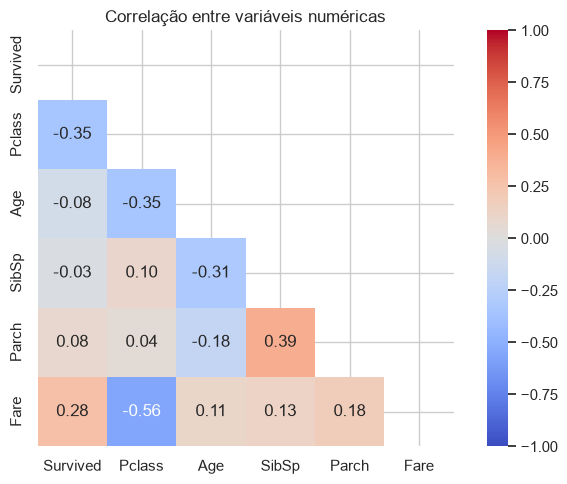

In [23]:
num = train[["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]]
corr = num.corr(numeric_only=True)

# máscara: mostra só o triângulo de baixo (o de cima é repetido)
mascara = np.triu(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(corr, mask=mascara, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Correlação entre variáveis numéricas")
plt.tight_layout()
plt.show()

> 💡 **Como ler:** valores perto de ±1 = relação forte; perto de 0 = sem relação **linear**. Aqui `Pclass` e `Fare` têm correlação negativa forte (classe de número menor = tarifa maior), o que é esperado. Com o target: `Pclass` (negativa, ≈ -0,35) e `Fare` (positiva, ≈ 0,28) são as mais relacionadas à sobrevivência entre as numéricas. Duas variáveis muito correlacionadas entre si (**multicolinearidade**) podem atrapalhar modelos lineares.
>
> ⚠️ **Limite:** correlação só vê relação linear e só serve para números. Para pares categoria × target, use as taxas e o teste qui-quadrado (seção 12).

### 10.5 Visão geral de uma vez → **pairplot**

Útil no começo para "bater o olho" em tudo. Em datasets grandes, use uma amostra.

> 💡 **Dica:** o pairplot funciona melhor com numéricas **contínuas**. `Pclass` é categoria ordinal, então aparece como "linhas" de pontos. Isso é esperado, não é erro.

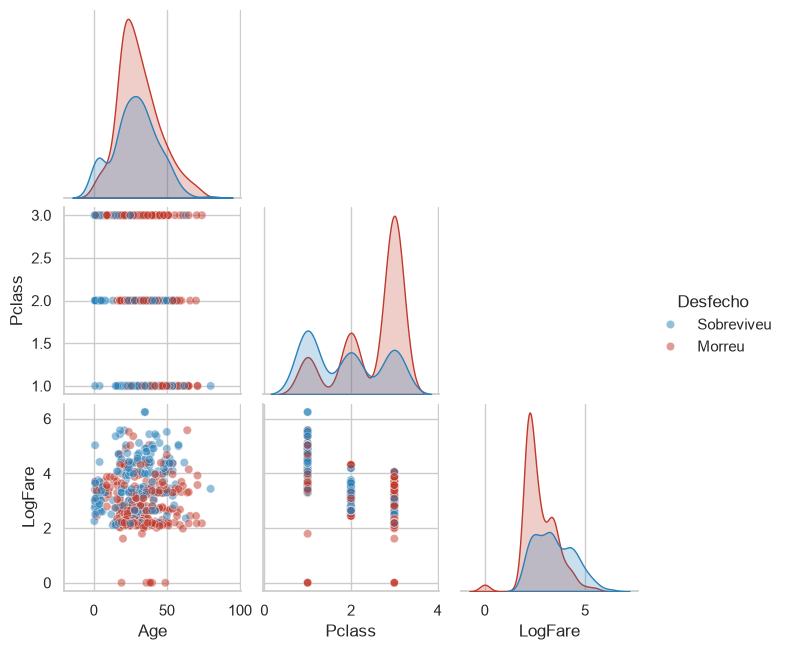

In [24]:
amostra = train[["Desfecho", "Age", "Fare", "Pclass"]].dropna()
amostra = amostra.assign(LogFare=np.log1p(amostra["Fare"])).drop(columns="Fare")
sns.pairplot(amostra, hue="Desfecho", palette=PALETA_SURV, corner=True,
             plot_kws={"alpha": 0.5}, height=2.2)
plt.show()

## 11. Ideias de novas features (feature engineering)

A EDA aponta **quais variáveis novas valem criar**. Aqui só **exploramos** se a ideia tem sinal; a criação "para valer" (aplicada a treino e teste) fica no notebook de modelagem.

| Ideia | De onde vem | Hipótese |
|---|---|---|
| `Title` | extrair de `Name` (Mr, Mrs, Miss, Master) | carrega sexo, idade e estado civil; "Master" = menino |
| `FamilySize` | `SibSp + Parch + 1` | famílias médias se ajudam; sozinho ou família enorme sofre |
| `IsAlone` | `FamilySize == 1` | viajar sozinho tem efeito próprio |
| `HasCabin` | `Cabin` não nulo | ter cabine registrada indica classe alta |
| `LogFare` | `log1p(Fare)` | reduz assimetria |

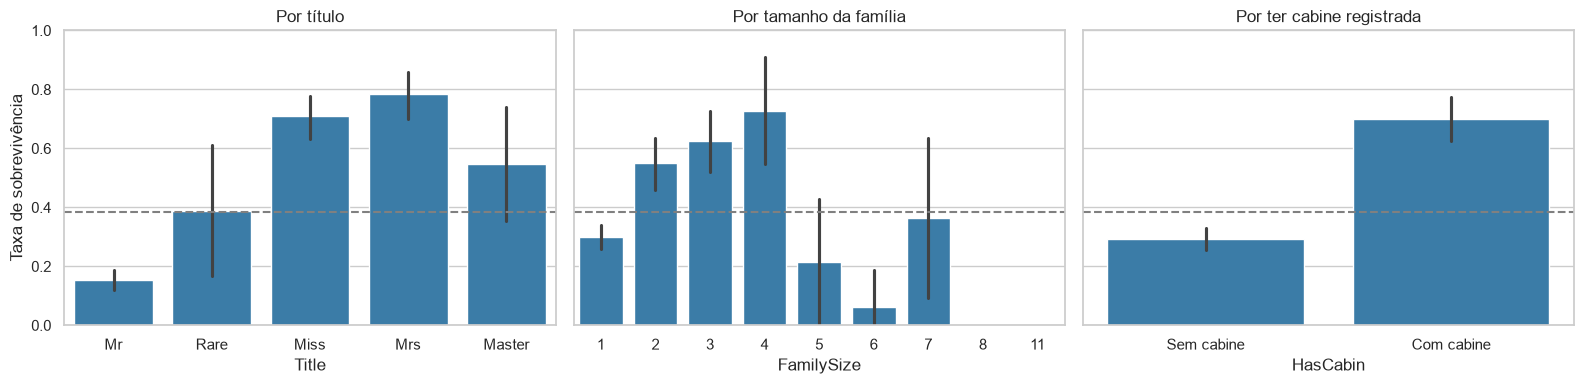

FamilySize
1     434
2     129
3      77
4      22
5      14
6      16
7      11
8       4
11      5
Name: count, dtype: int64


In [25]:
eda = train.copy()   # cópia só para explorar

# Title: pega a palavra entre a vírgula e o ponto. Ex.: "Braund, Mr. Owen" -> "Mr"
eda["Title"] = eda["Name"].str.extract(r",\s*([^\.]+)\.", expand=False).str.strip()
eda["Title"] = eda["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
comuns = ["Mr", "Mrs", "Miss", "Master"]
eda.loc[~eda["Title"].isin(comuns), "Title"] = "Rare"

eda["FamilySize"] = eda["SibSp"] + eda["Parch"] + 1
eda["IsAlone"] = (eda["FamilySize"] == 1).astype(int)
eda["HasCabin"] = eda["Cabin"].notna().astype(int)

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
ordem_titulo = ["Mr", "Rare", "Miss", "Mrs", "Master"]
sns.barplot(data=eda, x="Title", y="Survived", order=ordem_titulo, color="#2980b9", ax=axes[0])
axes[0].set_title("Por título")
sns.barplot(data=eda, x="FamilySize", y="Survived", color="#2980b9", ax=axes[1])
axes[1].set_title("Por tamanho da família")
sns.barplot(data=eda, x="HasCabin", y="Survived", color="#2980b9", ax=axes[2])
axes[2].set_xticklabels(["Sem cabine", "Com cabine"])
axes[2].set_title("Por ter cabine registrada")
for ax in axes:
    ax.set_ylabel("Taxa de sobrevivência")
    ax.set_ylim(0, 1)
    ax.axhline(train["Survived"].mean(), color="gray", ls="--")
plt.tight_layout()
plt.show()

print(eda["FamilySize"].value_counts().sort_index())

> 🧠 **Insights a verificar no gráfico:**
> - `Title`: **"Master"** (meninos) e **Miss/Mrs** sobrevivem muito mais que **Mr**. O título resume sexo + idade + estado civil em uma coluna.
> - `FamilySize`: famílias de 2 a 4 pessoas têm taxa maior; **sozinho** e famílias **muito grandes (5+)** têm taxa menor (relação **não linear**: um modelo linear puro não captura isso sem ajuda; árvores capturam).
> - `HasCabin`: quem tem cabine registrada sobrevive bem mais. Cuidado: é **efeito de classe social**, não da cabine em si.

> 💡 **Dica (como achar boas features):** pergunte *"que informação está escondida nesta coluna?"* (nomes têm título, bilhetes têm prefixos, datas têm dia da semana) e *"que combinação de colunas faria mais sentido junta?"* (família = irmãos + pais + eu).

✍️ **Sua vez:** crie uma ideia própria (ex.: `Tarifa por pessoa = Fare / FamilySize`; ou o prefixo do `Ticket`) e veja se tem relação com `Survived`.

## 12. Testes de hipótese

Os gráficos mostram **diferenças**; os testes dizem se elas podem ser **coincidência**.

**Qual teste usar?**

| Variável | Target | Teste | Pergunta |
|---|---|---|---|
| Categórica | Categórico (0/1) | **Qui-quadrado** | "São independentes?" |
| Numérica (assimétrica) | Categórico (0/1) | **Mann-Whitney** | "Os dois grupos têm distribuições diferentes?" |
| Numérica (≈ normal) | Categórico (0/1) | **Teste t** | "As médias são diferentes?" |

Como `Age` e `Fare` não são normais, usamos **Mann-Whitney** (não assume distribuição normal).

**Como ler:** H0 = "não há relação". **p < 0,05** → rejeitamos H0 (há evidência de relação). Mas lembre: **p-valor não mede o tamanho do efeito** e **não é a probabilidade de H0 ser verdadeira**. Por isso calculamos também o **V de Cramér** (0 = nenhuma associação, 1 = perfeita).

In [26]:
def teste_categorica(col):
    tabela = pd.crosstab(train[col], train["Survived"])
    chi2, p, _, _ = chi2_contingency(tabela)
    n = tabela.values.sum()
    k = min(tabela.shape) - 1
    cramer_v = np.sqrt(chi2 / (n * k))
    return {"variável": col, "teste": "qui-quadrado", "p-valor": p, "tamanho do efeito (V de Cramér)": cramer_v}

def teste_numerica(col):
    g0 = train.loc[train["Survived"] == 0, col].dropna()
    g1 = train.loc[train["Survived"] == 1, col].dropna()
    u, p = mannwhitneyu(g1, g0)      # g1 primeiro: u conta os pares em que o sobrevivente tem o valor maior
    # tamanho do efeito: probabilidade de um sobrevivente ter valor maior que um não sobrevivente
    # (0,50 = nenhuma diferença; longe de 0,50 = diferença grande)
    prob = u / (len(g0) * len(g1))
    return {"variável": col, "teste": "Mann-Whitney", "p-valor": p, "tamanho do efeito (V de Cramér)": np.nan,
            "P(sobrev. > não sobrev.)": prob}

resultados = [teste_categorica(c) for c in ["Sex", "Pclass", "Embarked"]]
resultados += [teste_numerica(c) for c in ["Age", "Fare"]]
tabela_testes = pd.DataFrame(resultados)
tabela_testes["significativo (p<0,05)?"] = np.where(tabela_testes["p-valor"] < 0.05, "sim", "não")
tabela_testes["p-valor"] = tabela_testes["p-valor"].map(lambda x: f"{x:.2e}")   # notação científica: 1.2e-05 = 0,000012
tabela_testes.round(3)

,variável,teste,p-valor,tamanho do efeito (V de Cramér),P(sobrev. > não sobrev.),"significativo (p<0,05)?"
0,Sex,qui-quadrado,4.16e-48,0.546,NaN,sim
1,Pclass,qui-quadrado,1.89e-19,0.348,NaN,sim
2,Embarked,qui-quadrado,2.17e-06,0.192,NaN,sim
3,Age,Mann-Whitney,2.24e-01,NaN,0.470,não
4,Fare,Mann-Whitney,6.89e-20,NaN,0.703,sim


**Como interpretar (exemplo, `Sex`):** *"O p-valor é muito menor que 0,05: se sexo e sobrevivência fossem independentes, seria extremamente improvável ver uma diferença tão grande. Rejeito H0. O V de Cramér é alto, então o efeito é **grande**, não só estatisticamente significativo."*

**Repare no caso de `Age`:** o teste **não** deu significativo no geral (p ≈ 0,22), mas na seção 9.2 vimos que **crianças** sobrevivem bem mais. O efeito está concentrado em uma faixa e **some quando olhamos a idade inteira**. Moral: um teste "não significativo" não quer dizer "a variável não importa"; pode ser que o efeito esteja escondido em um subgrupo (e que modelos de árvore ou uma feature como `FaixaIdade` consigam capturar).

> 💡 **Dica (armadilhas comuns):**
> - **Muitos testes = mais chance de falso positivo.** Se testar 20 coisas, uma "dá significativo" por acaso. Formule hipóteses **antes** de testar, não procure significância no escuro.
> - **Significativo ≠ importante.** Com muitos dados, diferenças minúsculas têm p pequeno. Sempre olhe o **tamanho do efeito**.
> - **Associação ≠ causa.** Que `Sex` se associe à sobrevivência não significa que o sexo "causou" nada; é o protocolo de evacuação.

✍️ **Sua vez:** escreva uma frase para cada linha da tabela: *"[variável] tem relação com sobrevivência? Com que força?"*

## 13. Conclusões e próximos passos

### Resumo dos principais achados (preencha com suas palavras)
> Modelo de escrita: *"Descobri que [achado] (evidência: [gráfico/número/teste]). Isso sugere [implicação para o modelo]."*

1. **Target:** ~38% sobreviveram → classes levemente desbalanceadas; o baseline burro acerta ~62%.
2. **Sexo:** __________________________________________
3. **Classe:** __________________________________________
4. **Idade:** __________________________________________
5. **Família / título / cabine:** __________________________________________

### Decisões de tratamento (para o notebook de modelagem)
| Problema | Decisão |
|---|---|
| `Age` com ~20% de nulos | preencher com a **mediana do treino** |
| `Embarked` com poucos nulos | preencher com a **moda do treino** |
| `Cabin` com ~77% de nulos | criar `HasCabin` e descartar o texto |
| `Fare` muito assimétrica, outliers reais | manter e aplicar `log1p` |
| Categorias sem ordem (`Embarked`, `Title`) | **one-hot** |
| Variáveis em escalas diferentes | padronizar (`StandardScaler`, ajustado só no treino) |

### Limitações (mostra senso crítico, cite na entrevista)
- **Viés de amostra:** só temos quem estava a bordo; não generaliza para "pessoas em geral".
- **Dados faltantes em `Age`:** a imputação pela mediana é uma simplificação.
- Todos os achados são **associações**, não causas.

### Próximos passos
- `03_modelos.ipynb`: criar as features, treinar regressão logística, árvore e boosting, e comparar com as métricas.
- Voltar ao `test` **somente** na avaliação final.

---
### ✅ Checklist antes de commitar
- [x] Restart Kernel + Run All roda sem erro
- [x] Todos os gráficos têm título, eixos legíveis e cores consistentes
- [ ] Preenchi os blocos "✍️ Sua vez" e a seção de conclusões
- [x] `data/` está no `.gitignore`
- [ ] Mensagem de commit clara (ex.: `feat: add EDA notebook`)